# Stroke Prediction Project

## Introduction

A stroke, sometimes called a brain attack, occurs when something blocks blood supply to part of the brain or when a blood vessel in the brain bursts. In either case, parts of the brain become damaged or die. A stroke can cause lasting brain damage, long-term disability, or even death. 

To work properly, your brain needs oxygen. Your arteries deliver oxygen-rich blood to all parts of your brain. If something happens to block the flow of blood, brain cells start to die within minutes, because they can't get oxygen. This causes a stroke. (Source: https://www.cdc.gov/stroke/about/index.html)

Stroke is a leading cause of death and disability worldwide. Globally, 1 in 4 adults over the age of 25 will have a stroke in their lifetime. The incidence of stroke increases significantly with age, however over 60% of strokes happen to people under the age of 70 and 16% happen to those under the age of 50. (Source: https://www.world-stroke.org/world-stroke-day-campaign/about-stroke/impact-of-stroke)

Early identification of individuals at high risk of stroke can enhance preventative care, allowing timely interventions that reduce mortality, lower healthcare costs, and improve outcomes for the patient.

The goal of this project is to make a model which would predict if a patient had a stroke, based on available data. Predictions from model can be used for predicting if a patient is in risk of having a stroke in the future. Data is taken from Kaggle (https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset/data).

**Dataset information**

The dataset contains 5,110 patient records with 12 features (one of the is index column), including demographic information (e.g., gender, age), medical conditions (e.g., hypertension, heart disease), lifestyle factors (e.g., smoking status), and health metrics (e.g., BMI, glucose levels). The dataset has some missing values, especially in the BMI feature.

**Project**

Stroke Prediction Dataset is used for Gradient Boosted Trees & Feature Engineering project of Machine Learning module sprint 2. Data analysis is done using python and pandas library. Modeling is done using scikit-learn, lightgbm and xgboost. For visualization matplotlib and seaborn libraries were used. The project is done using Jupyter notebooks (4.2.4).

The project is done using python (version 3.11.4), numpy (2.0.1), seaborn (0.13.2), matplotlib (3.9.1), missingno (0.5.2), pandas (2.2.2), imbalanced-learn (0.12.3), lightgbm (4.5.0), scikit-learn (1.5.1), statsmodels (0.14.2), scipy (1.14.0), xgboost (2.1.1), Flask (3.0.3), joblib (1.4.2) and requests (2.32.3) libraries.

**Project goal**
The goal of this project is to develop a machine learning model that predicts whether a patient is at risk of having a stroke

**Plan**

First, I will do exploratory data analysis.

Second, I will look into three questions, regarding the features: 
* Is there a significant difference in BMI between patients who had a stroke or not?
* Is age an important factor when predicting stroke?
* Is there a difference between males and females in regards to getting a stroke?

And I will try to answer them using hypothesis testing and use results for modeling.

Third, I will create few models and tune their hyper-parameters. After tuning the best model will be chosen, based on recall, as the goal is to predict as many people who had stroke as possible.

Lastly the best model will be deployed using your own computer as a server.

### Importing dataset and packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
import statsmodels.api as sm
import xgboost as xgb
import joblib
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as Pipe
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from scipy import stats
from scripts import *

In [2]:
data = pd.read_csv('data/healthcare-dataset-stroke-data.csv', index_col=0)
data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
id,,,,,,,,,,,
9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
data.shape

(5110, 11)

## Checking for nulls and duplicates and other data cleaning

In [4]:
data.duplicated().any()

np.False_

In [5]:
nullresults = data.isnull().sum()
nullresults

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [6]:
print(f'The percentage of missing BMI values is {count_percentage(nullresults.bmi, data.shape[0])}')

The percentage of missing BMI values is 3.93


There is some missing data about some persons BMI. It will be filled in using median method later when modeling.

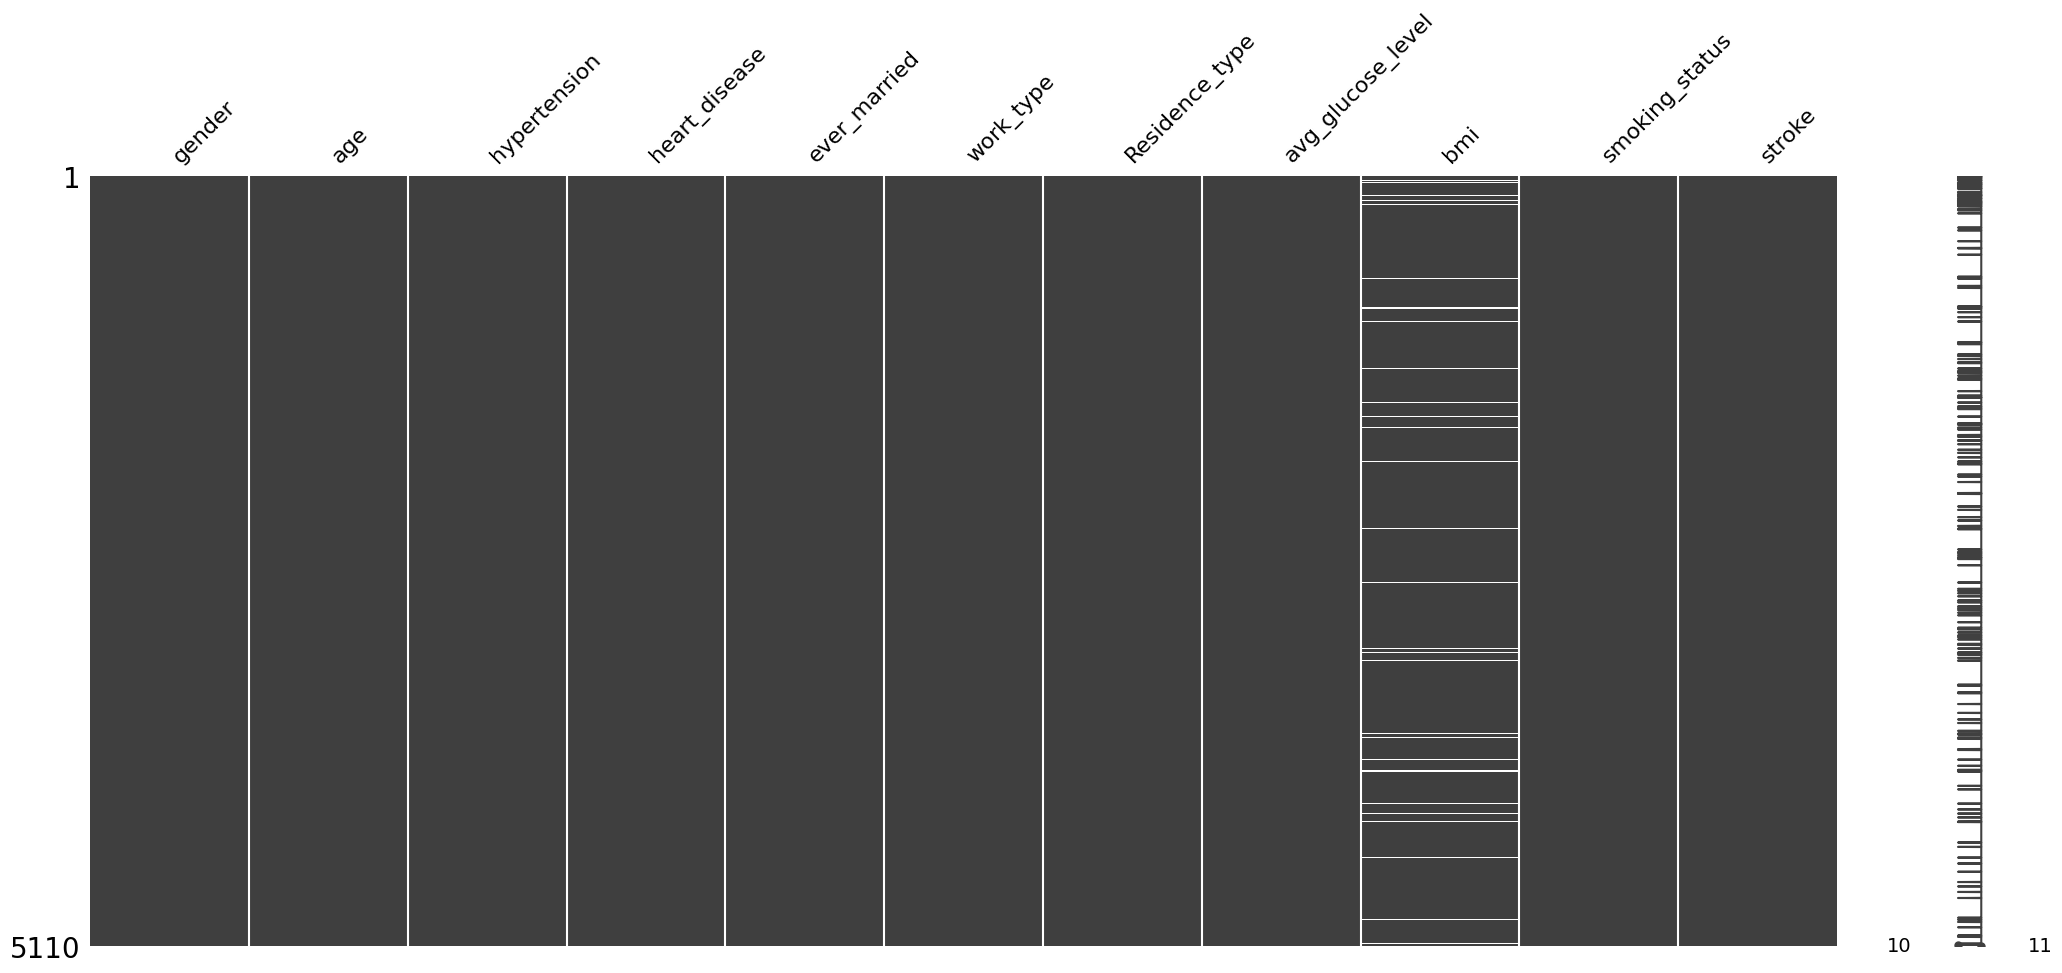

In [7]:
%matplotlib inline
msno.matrix(data);

# Exploring data

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5110 entries, 9046 to 44679
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 479.1+ KB


Attribute Information

1) id: unique identifier
2) gender: "Male", "Female" or "Other"
3) age: age of the patient
4) hypertension: 0 if the patient doesn't have hypertension, 1 if the patient has hypertension
5) heart_disease: 0 if the patient doesn't have any heart diseases, 1 if the patient has a heart disease
6) ever_married: "No" or "Yes"
7) work_type: "children", "Govt_jov", "Never_worked", "Private" or "Self-employed"
8) Residence_type: "Rural" or "Urban"
9) avg_glucose_level: average glucose level in blood
10) bmi: body mass index
11) smoking_status: "formerly smoked", "never smoked", "smokes" or "Unknown"*
12) stroke: 1 if the patient had a stroke or 0 if not

*Note: "Unknown" in smoking_status means that the information is unavailable for this patient

In [9]:
for i in data.columns:
    print(i, "column's total unique values are:", data[i].nunique())

gender column's total unique values are: 3
age column's total unique values are: 104
hypertension column's total unique values are: 2
heart_disease column's total unique values are: 2
ever_married column's total unique values are: 2
work_type column's total unique values are: 5
Residence_type column's total unique values are: 2
avg_glucose_level column's total unique values are: 3979
bmi column's total unique values are: 418
smoking_status column's total unique values are: 4
stroke column's total unique values are: 2


In [10]:
features_cat = data.select_dtypes(include=['object', 'int64']).columns

for i in features_cat:
    print(i, "column's unique values are:", data[i].unique())

gender column's unique values are: ['Male' 'Female' 'Other']
hypertension column's unique values are: [0 1]
heart_disease column's unique values are: [1 0]
ever_married column's unique values are: ['Yes' 'No']
work_type column's unique values are: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type column's unique values are: ['Urban' 'Rural']
smoking_status column's unique values are: ['formerly smoked' 'never smoked' 'smokes' 'Unknown']
stroke column's unique values are: [1 0]


In [11]:
data.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [12]:
gender_counts = data['gender'].value_counts()
hypertension_counts = data['hypertension'].value_counts()
heart_disease_counts = data['heart_disease'].value_counts()
ever_married_counts = data['ever_married'].value_counts()
work_type_counts = data['work_type'].value_counts()
residence_type_counts = data['Residence_type'].value_counts()
smoking_status_counts = data['smoking_status'].value_counts()
stroke_counts = data['stroke'].value_counts()

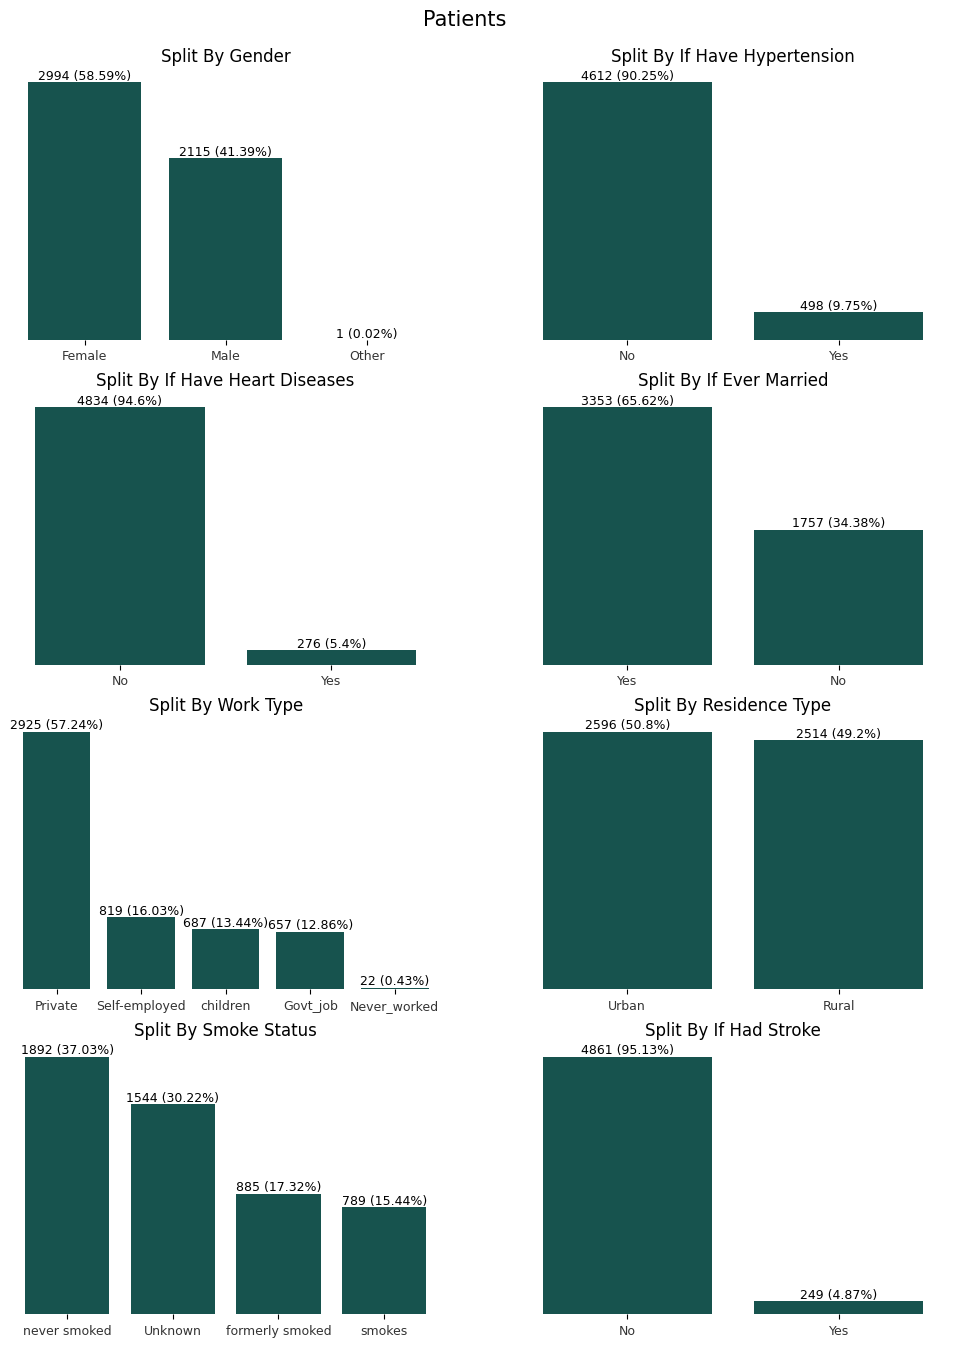

In [13]:
fig, axs = plt.subplots(4, 2, figsize=(12, 15))

fig.suptitle('Patients', fontsize=15)
fig.subplots_adjust(top=0.94)

ax1 = bar_plot_f_perc(gender_counts, 'Split By Gender', color='#0D5D56', ax=axs[0, 0])
ax2 = bar_plot_f_perc(hypertension_counts, 'Split By If Have Hypertension', color='#0D5D56', ax=axs[0, 1])
ax3 = bar_plot_f_perc(heart_disease_counts, 'Split By If Have Heart Diseases', color='#0D5D56', ax=axs[1, 0])
ax4 = bar_plot_f_perc(ever_married_counts, 'Split By If Ever Married', color='#0D5D56', ax=axs[1, 1])
ax5 = bar_plot_f_perc(work_type_counts, 'Split By Work Type', color='#0D5D56', ax=axs[2, 0])
ax6 = bar_plot_f_perc(residence_type_counts, 'Split By Residence Type', color='#0D5D56', ax=axs[2, 1])
ax7 = bar_plot_f_perc(smoking_status_counts, 'Split By Smoke Status', color='#0D5D56', ax=axs[3, 0])
ax8 = bar_plot_f_perc(stroke_counts, 'Split By If Had Stroke', color='#0D5D56', ax=axs[3, 1])

ax2.set_xticklabels(['No', 'Yes'])
ax3.set_xticklabels(['No', 'Yes'])
ax8.set_xticklabels(['No', 'Yes']);

We can see that some of the categories are rare and therefore the dataset is unbalanced. Only 4.87% of patients had stroke in this dataset.

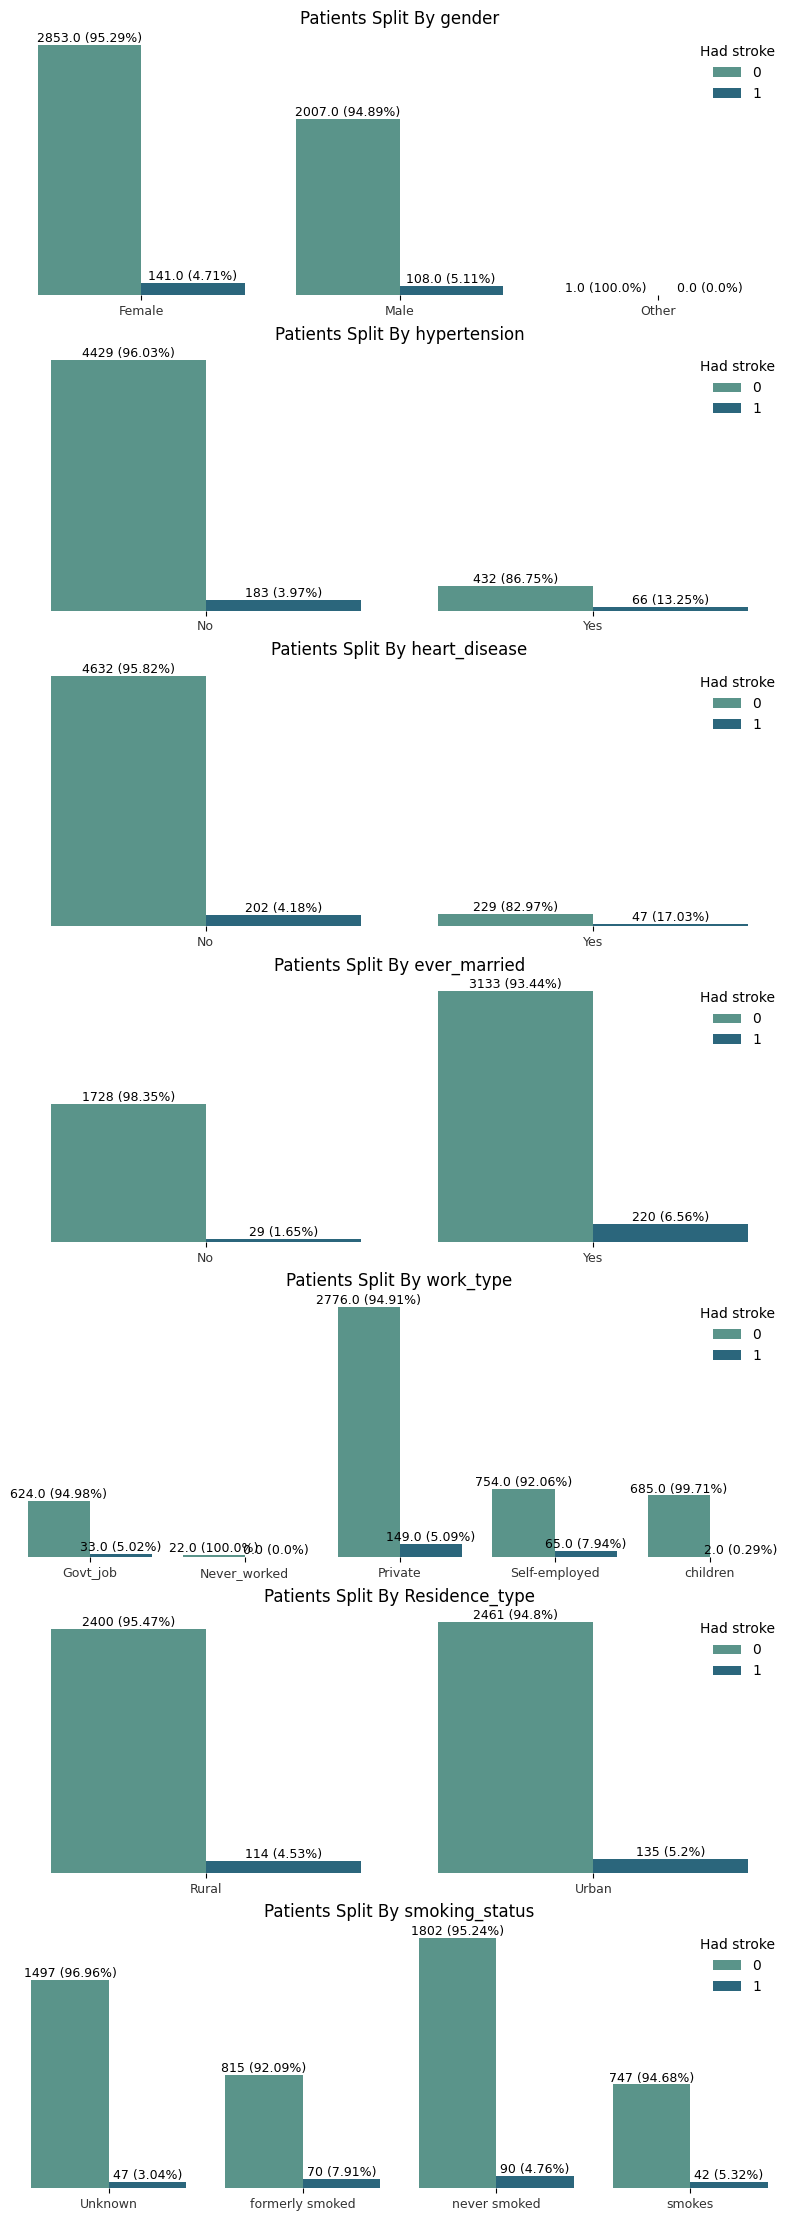

In [14]:
# Selecting all categorical features except if the patient had a stroke
features = features_cat[:-1]

fig, axs = plt.subplots(len(features), 1, figsize=(10, (4 * len(features))))

i = 0
for item in features:
    temp = data.groupby(item)['stroke'].value_counts()
    ax = bar_plot_multi_index_f(temp, item, 'stroke', f'Patients Split By {item}', 'crest', ax=axs[i])
    ax.legend(edgecolor='none', title='Had stroke')
    if item in ['hypertension', 'heart_disease']:
        ax.set_xticklabels(['No', 'Yes'])
    i += 1

There seems to to be tendencies that patients who have hypertension, heart disease and are self employed have higher chance for stroke. There is also tendency that formerly smoked and married patients have also increased chance for stroke, but it might be in part due to fact that these patients are likely to be older, as people get married later and they also might quit smoking in later stages of life.

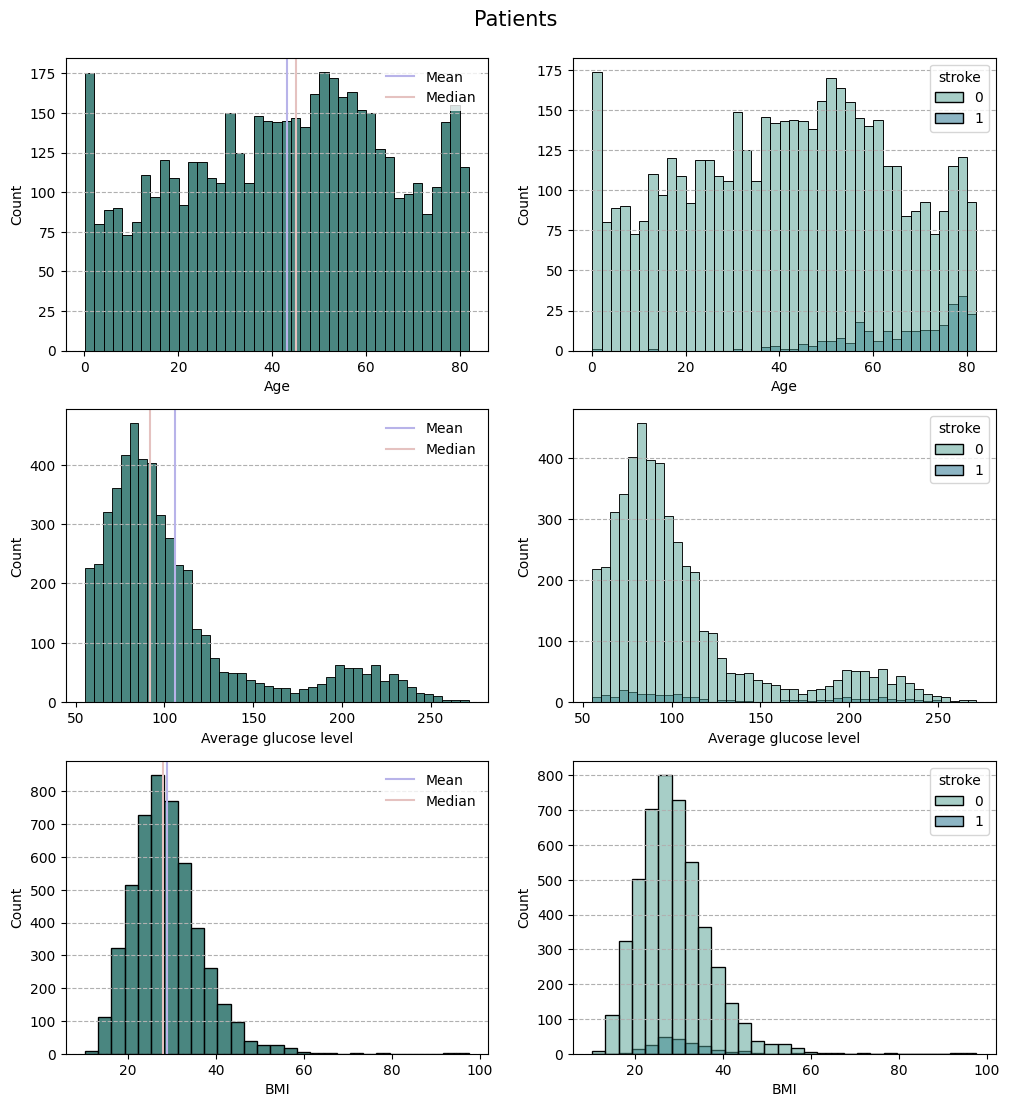

In [15]:
fig, axs = plt.subplots(3, 2, figsize=(12, 12))

fig.suptitle('Patients', fontsize=15)
fig.subplots_adjust(top=0.94)

ax00 = histplot_f(data.age, color='#0D5D56', color_median='#E5C2C0', binwidth=2, ax=axs[0, 0])
ax00.set(xlabel='Age')
ax01 = simple_histplot(data, 'age', xlabel='Age', hue='stroke', palette='crest', binwidth=2, ax=axs[0, 1])

ax10 = histplot_f(data.avg_glucose_level, color='#0D5D56', color_median='#E5C2C0', binwidth=5, ax=axs[1, 0])
ax10.set(xlabel='Average glucose level')
ax11 = simple_histplot(
    data, 'avg_glucose_level', xlabel='Average glucose level', hue='stroke', palette='crest', binwidth=5, ax=axs[1, 1]
)

ax20 = histplot_f(data.bmi, color='#0D5D56', color_median='#E5C2C0', binwidth=3, ax=axs[2, 0])
ax20.set(xlabel='BMI')
ax21 = simple_histplot(data, 'bmi', xlabel='BMI', hue='stroke', palette='crest', binwidth=3, ax=axs[2, 1])

There is high increase of strokes with age of the patient. Higher average glucose level also seems to be causing higher chances for strokes.

Due to not having a lot of samples, one patient with other gender will be removed from the dataset for modeling. Also there are only 22 patients who have never worked. They also will be removed from the dataset.

In [16]:
data = data.drop(data[data['gender'] == 'Other'].index)
data = data.drop(data[data['work_type'] == 'Never_worked'].index)

In [17]:
data['ever_married'] = data['ever_married'].map({'Yes': 1, 'No': 0})
data['gender'] = data['gender'].map({'Male': 1, 'Female': 0})
data['Residence_type'] = data['Residence_type'].map({'Urban': 1, 'Rural': 0})

In [18]:
x_num = data.select_dtypes(exclude='object').reset_index(drop=True)
x_cat = data.select_dtypes(include='object')

encoder = OneHotEncoder(sparse_output=False)
x_encoded = encoder.fit_transform(x_cat)

# create the names for the one-hot encoded categorical features
categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

# put the features into a dataframe and join with the original
# numerical features

one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)
one_hot_features = one_hot_features.drop(['smoking_status_Unknown'], axis=1)
data_enc = x_num.join(one_hot_features)

# Putting stroke column last for convience
cols = data_enc.columns.tolist()
cols = cols[:8] + cols[9:] + cols[8:9]

data_enc = data_enc[cols]
data_enc.head(10).T

,0,1,2,3,4,5,6,7,8,9
gender,1.00,0.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,0.00
age,67.00,61.00,80.00,49.00,79.00,81.00,74.00,69.00,59.00,78.00
hypertension,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,0.00
heart_disease,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
ever_married,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,1.00
Residence_type,1.00,0.00,0.00,1.00,0.00,1.00,0.00,1.00,0.00,1.00
avg_glucose_level,228.69,202.21,105.92,171.23,174.12,186.21,70.09,94.39,76.15,58.57
bmi,36.60,NaN,32.50,34.40,24.00,29.00,27.40,22.80,NaN,24.20
work_type_Govt_job,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
work_type_Private,1.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00


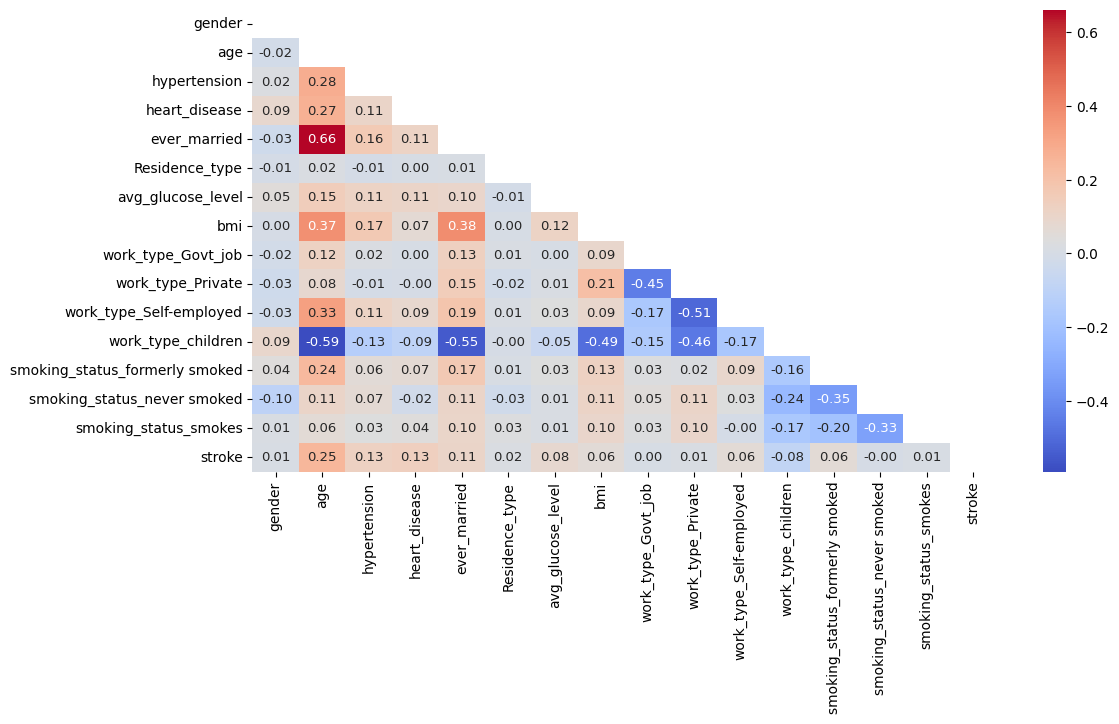

In [19]:
# Spearman correlation assumes monotonic relationships
corr = data_enc.corr(method='spearman')

fig = plt.figure(figsize=(12, 6))

# To make a triangle mask
mask = np.triu(np.ones_like(corr))

corr_plot = sns.heatmap(
    corr,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    annot=True,
    annot_kws={"size": 38 / np.sqrt(len(corr))},
    fmt=".2f",
    mask=mask,
)

There is high correlation between marriage and age, and moderate correlation between age and self-employment work type and formerly smoked status. There is correlation between having a stroke and age. There is also weak correlation between stroke hypertension, heart disease and being married. Rest of features have very weak correlation to having a stroke stroke.

### Outliers

In [20]:
outliers = outlier_f(data_enc)
outliers.count()

gender                              0
age                                 0
hypertension                      498
heart_disease                     276
ever_married                        0
Residence_type                      0
avg_glucose_level                 627
bmi                               114
work_type_Govt_job                657
work_type_Private                   0
work_type_Self-employed           819
work_type_children                687
smoking_status_formerly smoked    884
smoking_status_never smoked         0
smoking_status_smokes             789
stroke                            249
dtype: int64

There are outliers in the dataset. The outliers are rarer categories (such as people having strokes). There are outliers in both BMI and average glucose levels.

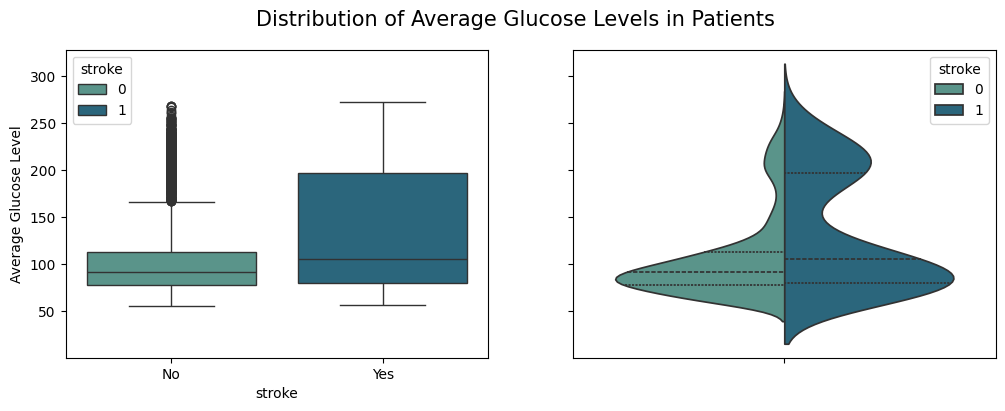

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle('Distribution of Average Glucose Levels in Patients', fontsize=15)

ax1 = sns.boxplot(y=data.avg_glucose_level, x=data.stroke, hue=data.stroke, palette='crest', ax=axs[0])
ax2 = sns.violinplot(y=data.avg_glucose_level, hue=data.stroke, split=True, inner="quart", palette='crest', ax=axs[1])

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Average Glucose Level');

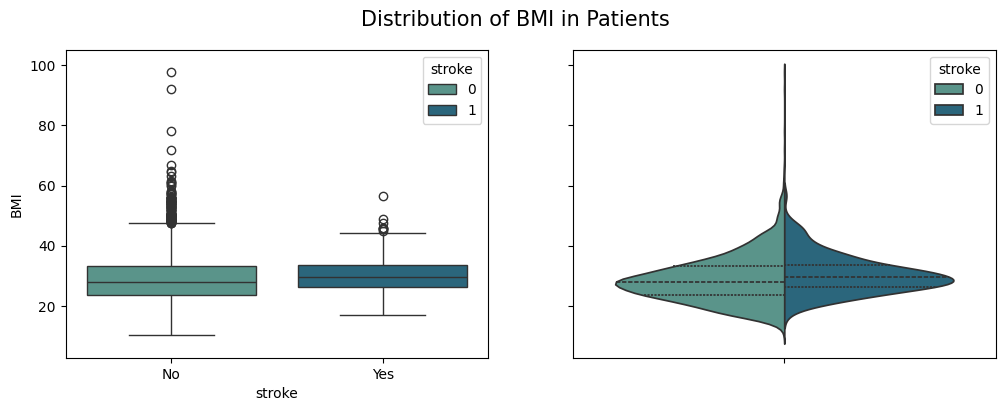

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle('Distribution of BMI in Patients', fontsize=15)

ax1 = sns.boxplot(y=data.bmi, x=data.stroke, hue=data.stroke, palette='crest', ax=axs[0])
ax2 = sns.violinplot(y=data.bmi, hue=data.stroke, split=True, inner="quart", palette='crest', ax=axs[1])

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('BMI');

There are outliers in both BMI and average glucose levels. All of outliers were kept in the dataset because they are valid data points.

# Perform statistical inference

After exploring the data, we are going to compare people who had the stroke and ones who didn't, using hypothesis testing. Here are 3 questions I will try to answer using statistics:

- Are people who have higher BMI more likely to have a stroke?
- Are elderly more likely suffer from stroke?
- Is there a difference in frequency of strokes depending on gender (male or female)?

We can try to answer these questions using the data. Hypothesis testing will be applied to check if there is any statistical significance. $ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are few hypotheses Bonferroni Correction will be used: $ α $ is going to be divided by the number of hypotheses made – 3 (which results to roughly 0.0167).

The results will determine whether or not the feature is going to be taken for modeling.

In [23]:
mask = data_enc['stroke'] == 1

had_stroke = data_enc[mask]
no_stroke = data_enc[~mask]

assert len(had_stroke) + len(no_stroke) == len(data_enc)

## Hypothesis 1

Are people who have higher BMI more likely to have a stroke?

$ H_0 $ will be that BMI isn't different for patients who had a stroke and ones who didn't. $ H_1 $ will be that there is a difference.

T test is going to be used to check if there is a statistical difference.

In [24]:
had_stroke_bmi = had_stroke.bmi.dropna()
had_stroke_bmi.describe()

count    209.000000
mean      30.471292
std        6.329452
min       16.900000
25%       26.400000
50%       29.700000
75%       33.700000
max       56.600000
Name: bmi, dtype: float64

In [25]:
no_stroke_bmi = no_stroke.bmi.dropna()
no_stroke_bmi.describe()

count    4677.000000
mean       28.839855
std         7.908240
min        10.300000
25%        23.500000
50%        28.000000
75%        33.100000
max        97.600000
Name: bmi, dtype: float64

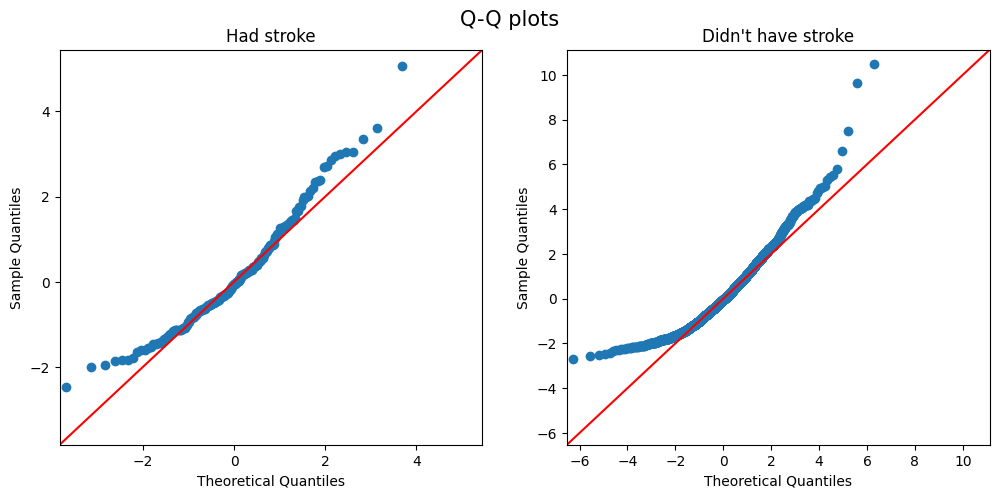

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

fig.suptitle('Q-Q plots', fontsize=15)
fig.subplots_adjust(top=0.90)

ax1 = sm.qqplot(had_stroke_bmi, stats.t, fit=True, line="45", ax=axs[0])
ax2 = sm.qqplot(no_stroke_bmi, stats.t, fit=True, line="45", ax=axs[1])

axs[0].set_title('Had stroke')
axs[1].set_title("Didn't have stroke");

We can see some deviations from theoretical quantiles, which indicates that the distributions are not normal as they are rather over-dispersed. The distribution is closer to normal for patients who had a stroke, than those who didn't.

However, since we have a lot of observations we can also apply central limit theorem and test hypothesis.

In [27]:
hyphotesis_tests_f(
    had_stroke_bmi, no_stroke_bmi, p=0.0167, name_x='Patients who had stroke', name_y="Patients who didn't have stroke"
)

95% confidence intervals:

Patients who had stroke
(np.float64(29.608163593319265), np.float64(31.33442013873815))
Patients who didn't have stroke
(np.float64(28.613151902181066), np.float64(29.066557313127895))
Invervals do not overlap.

Set p value is 0.0167.

TtestResult(statistic=np.float64(2.940493283315355), pvalue=np.float64(0.0032922775182084555), df=np.float64(4884.0))
t test results are statistically significant

MannwhitneyuResult(statistic=np.float64(565466.0), pvalue=np.float64(0.00012044923068679968))
Mann–Whitney U test results are statistically significant

MedianTestResult(statistic=np.float64(8.019669091663049), pvalue=np.float64(0.004627202410104093), median=np.float64(28.1), table=array([[ 124, 2295],
       [  85, 2382]]))
Median test results are statistically significant


According to the results of hypothesis testing, there is a statistical difference in BMI between patients who had a stroke and who didn't. Patients with higher BMI are at greater risk for stroke.

## Hypothesis 2

Are elderly more likely suffer from stroke?

$ H_0 $ will be that age isn't different for patients who had a stroke and ones who didn't. $ H_1 $ will be that there is a difference.

T test is going to be used to check if there is a statistical difference.

In [28]:
had_stroke_age = had_stroke.age
had_stroke_age.describe()

count    249.000000
mean      67.728193
std       12.727419
min        1.320000
25%       59.000000
50%       71.000000
75%       78.000000
max       82.000000
Name: age, dtype: float64

In [29]:
no_stroke_age = no_stroke.age
no_stroke_age.describe()

count    4838.000000
mean       42.092121
std        22.275038
min         0.080000
25%        24.000000
50%        43.000000
75%        59.000000
max        82.000000
Name: age, dtype: float64

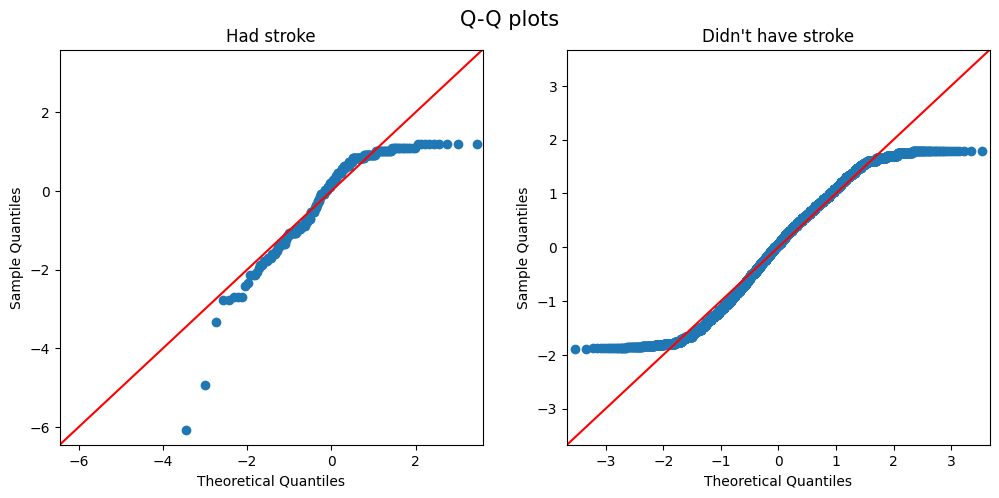

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

fig.suptitle('Q-Q plots', fontsize=15)
fig.subplots_adjust(top=0.90)

ax1 = sm.qqplot(had_stroke_age, stats.t, fit=True, line="45", ax=axs[0])
ax2 = sm.qqplot(no_stroke_age, stats.t, fit=True, line="45", ax=axs[1])

axs[0].set_title('Had stroke')
axs[1].set_title("Didn't have stroke");

We can see some deviations from theoretical quantiles, which indicates that the distributions are not normal. The distribution is closer to normal for patients who didn't have a stroke, compared to ones who had.

However, since we have a lot of observations we can also apply central limit theorem and test hypothesis.

In [31]:
hyphotesis_tests_f(
    had_stroke_age, no_stroke_age, p=0.0167, name_x='Patients who had stroke', name_y="Patients who didn't have stroke"
)

95% confidence intervals:

Patients who had stroke
(np.float64(66.13959719887826), np.float64(69.31678834329041))
Patients who didn't have stroke
(np.float64(41.46429037875763), np.float64(42.7199510433176))
Invervals do not overlap.

Set p value is 0.0167.

TtestResult(statistic=np.float64(18.008915040115422), pvalue=np.float64(2.4424792010705797e-70), df=np.float64(5085.0))
t test results are statistically significant

MannwhitneyuResult(statistic=np.float64(1004440.0), pvalue=np.float64(7.916374461816001e-71))
Mann–Whitney U test results are statistically significant

MedianTestResult(statistic=np.float64(217.763843917343), pvalue=np.float64(2.7807205420811493e-49), median=np.float64(45.0), table=array([[ 236, 2256],
       [  13, 2582]]))
Median test results are statistically significant


According to the results of hypothesis testing, there is a statistical difference in age between patients who had a stroke and who didn't. Elderly are at greater risk for stroke.

## Hypothesis 3

Is there a difference in frequency of strokes depending on gender (male or female)?

$ H_0 $ will be that there is no difference between genders. $ H_1 $ will be that there is a difference.

Chi-square test is going to be used to check if there is a statistical difference

In [32]:
genders = data.groupby('stroke').gender.value_counts()
genders = genders.unstack().rename(columns={0: 'Female', 1: 'Male'}, index={0: 'No', 1: 'Yes'})
genders

gender,Female,Male
stroke,,
No,2842,1996
Yes,141,108


In [33]:
stats.chi2_contingency(genders)

Chi2ContingencyResult(statistic=np.float64(0.3545756340499542), pvalue=np.float64(0.5515343332183202), dof=1, expected_freq=array([[2836.98722233, 2001.01277767],
       [ 146.01277767,  102.98722233]]))

Statistically, there wasn't a significant difference between males and females when getting a stroke. Both genders are equally at risk. However, the feature will not be excluded from modeling as it might be important factor together with another feature.

# Modeling

Majority of patients did not have stroke (95.13%). The goal of the model is to have as high as possible recall in order to get as many patients who are in risk of having a stroke.

## Dividing Data and Preparation

In [34]:
X = data_enc.drop(['stroke'], axis=1)
y = data_enc['stroke']

In [35]:
median = X.bmi.median()
X['bmi'] = X['bmi'].fillna(median)

X.isnull().any().any()

np.False_

In [36]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=data_enc["stroke"])

In [37]:
# Using oversampling and undersampling for balancing the data

over = SMOTE(sampling_strategy=1, random_state=0)
under = RandomUnderSampler(sampling_strategy=0.1, random_state=0)

steps = [('under', under), ('over', over)]
pipeline = Pipe(steps=steps)
x_train_o, y_train_o = pipeline.fit_resample(x_train, y_train)

In [38]:
def grid_search_f(model, param_grid, x, y, scoring='recall', showall=False):

    grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, scoring='recall', error_score=0)
    with np.errstate(invalid='ignore'):  # to ignore a bugged error message
        grid_result = grid_search.fit(x, y)

    # summarize results
    print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
    means = grid_result.cv_results_['mean_test_score']
    stds = grid_result.cv_results_['std_test_score']
    params = grid_result.cv_results_['params']
    if showall:
        for mean, stdev, param in zip(means, stds, params):
            print("%f (%f) with: %r" % (mean, stdev, param))
    return grid_search.best_params_

## Baseline classifier

Goal is to have higher recall for stroke patients than baseline model.

In [39]:
dummy_clf = DummyClassifier(strategy="uniform", random_state=0)

dummy_clf.fit(x_train, y_train)
yhat = dummy_clf.predict(x_train)

prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)
print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[1894 1976]
 [  95  104]]
              precision    recall  f1-score   support

           0       0.95      0.49      0.65      3870
           1       0.05      0.52      0.09       199

    accuracy                           0.49      4069
   macro avg       0.50      0.51      0.37      4069
weighted avg       0.91      0.49      0.62      4069



## Creating models

### Random Forest

**First version:** data with no oversampling used to train.

In [40]:
model = RandomForestClassifier(random_state=0)
n_estimators = [10, 15, 20, 50, 100]
max_features = ['sqrt', 'log2']
max_depth = [10, 15, 20, 25, 30, 50, None]

grid = dict(n_estimators=n_estimators, max_features=max_features, max_depth=max_depth)
best1f = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

Best: 0.025256 using {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 15}


**Second version:** data with oversampling used to train.

In [41]:
model = RandomForestClassifier(random_state=0)
n_estimators = [10, 15, 20, 50]
max_features = ['sqrt', 'log2']
max_depth = [10, 15, 20, 25, 30, 50, None]

grid = dict(n_estimators=n_estimators, max_features=max_features, max_depth=max_depth)
best2f = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

Best: 0.916583 using {'max_depth': 25, 'max_features': 'sqrt', 'n_estimators': 15}


**Third version:** data with scaling used to train.

In [42]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", RandomForestClassifier(random_state=0))])
n_estimators = [10, 15, 20, 50, 100]
max_features = ['sqrt', 'log2']
max_depth = [10, 15, 20, 25, 30, 50, None]

grid = dict(clf__n_estimators=n_estimators, clf__max_features=max_features, clf__max_depth=max_depth)
best3f = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

Best: 0.025256 using {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__n_estimators': 15}


**Fourth version:** data with oversampling and scaling used to train.

In [43]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", RandomForestClassifier(random_state=0))])
n_estimators = [10, 15, 20, 50, 100]
max_features = ['sqrt', 'log2']
max_depth = [10, 15, 20, 25, 30, 50, None]

grid = dict(clf__n_estimators=n_estimators, clf__max_features=max_features, clf__max_depth=max_depth)
best4f = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

Best: 0.916583 using {'clf__max_depth': 25, 'clf__max_features': 'sqrt', 'clf__n_estimators': 15}


Since scaling does not impact results, best random forest model was chosen without scaling.

In [44]:
%%time
best_forest = RandomForestClassifier(random_state=0)
best_forest.set_params(**best2f)
best_forest.fit(x_train_o, y_train_o)
yhat = best_forest.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[3794   76]
 [   4  195]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3870
           1       0.72      0.98      0.83       199

    accuracy                           0.98      4069
   macro avg       0.86      0.98      0.91      4069
weighted avg       0.99      0.98      0.98      4069

CPU times: total: 93.8 ms
Wall time: 89.8 ms


### XGBoost

**First version:** data with no oversampling used to train.

In [45]:
model = xgb.XGBClassifier(random_state=0)
n_estimators = [10, 20, 30, 50, 100]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.25, 0.5, 0.75, 1]
learning_rate = [0.1, 0.3, 0.5]

grid = dict(n_estimators=n_estimators, max_depth=max_depth, subsample=subsample, learning_rate=learning_rate)
best1x = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

Best: 0.165769 using {'learning_rate': 0.5, 'max_depth': 9, 'n_estimators': 30, 'subsample': 0.25}


**Second version:** data with oversampling used to train.

In [46]:
model = xgb.XGBClassifier(random_state=0)
n_estimators = [10, 20, 30, 50, 100]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.25, 0.5, 0.75, 1]
learning_rate = [0.1, 0.3, 0.5]

grid = dict(n_estimators=n_estimators, max_depth=max_depth, subsample=subsample, learning_rate=learning_rate)
best2x = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

Best: 0.920101 using {'learning_rate': 0.5, 'max_depth': 9, 'n_estimators': 100, 'subsample': 0.75}


**Third version:** data with scaling used to train.

In [47]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", xgb.XGBClassifier(random_state=0))])
n_estimators = [10, 20, 30, 50, 100]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.25, 0.5, 0.75, 1]
learning_rate = [0.1, 0.3, 0.5]

grid = dict(
    clf__n_estimators=n_estimators, clf__max_depth=max_depth, clf__subsample=subsample, clf__learning_rate=learning_rate
)
best3x = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

Best: 0.165769 using {'clf__learning_rate': 0.5, 'clf__max_depth': 9, 'clf__n_estimators': 30, 'clf__subsample': 0.25}


**Fourth version:** data with oversampling and scaling used to train.

In [48]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", xgb.XGBClassifier(random_state=0))])
n_estimators = [10, 20, 30, 50, 100]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.25, 0.5, 0.75, 1]
learning_rate = [0.1, 0.3, 0.5]

grid = dict(
    clf__n_estimators=n_estimators, clf__max_depth=max_depth, clf__subsample=subsample, clf__learning_rate=learning_rate
)
best4x = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

Best: 0.920101 using {'clf__learning_rate': 0.5, 'clf__max_depth': 9, 'clf__n_estimators': 100, 'clf__subsample': 0.75}


Scaling does not impact results for this model as well therefore, best model was chosen without scaling.

In [49]:
%%time
best_xgboost = xgb.XGBClassifier(random_state=0)
best_xgboost.set_params(**best2x)
best_xgboost.fit(x_train_o, y_train_o)
yhat = best_xgboost.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[3779   91]
 [   0  199]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3870
           1       0.69      1.00      0.81       199

    accuracy                           0.98      4069
   macro avg       0.84      0.99      0.90      4069
weighted avg       0.98      0.98      0.98      4069

CPU times: total: 2.77 s
Wall time: 362 ms


### LightGBM

**First version:** data with no oversampling used to train.

In [50]:
model = LGBMClassifier(random_state=0)
n_estimators = [10, 20, 30, 50]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.1, 0.25, 0.5, 0.75, 1]
learning_rate = [0.1]


grid = dict(max_depth=max_depth, subsample=subsample, n_estimators=n_estimators, learning_rate=learning_rate)
best1l = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 199, number of negative: 3870
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000238 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 635
[LightGBM] [Info] Number of data points in the train set: 4069, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048906 -> initscore=-2.967705
[LightGBM] [Info] Start training from score -2.967705
Best: 0.050256 using {'learning_rate': 0.1, 'max_depth': 11, 'n_estimators': 50, 'subsample': 0.1}


**Second version:** data with oversampling used to train.

In [51]:
model = LGBMClassifier(random_state=0)
max_depth = [2, 5, 7, 9, 11]
subsample = [0.1, 0.25, 0.5, 0.75, 1]
learning_rate = [0.1, 0.3]

grid = dict(max_depth=max_depth, subsample=subsample, learning_rate=learning_rate)
best2l = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1990, number of negative: 1990
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000654 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2302
[LightGBM] [Info] Number of data points in the train set: 3980, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Best: 0.908543 using {'learning_rate': 0.3, '

**Third version:** data with scaling used to train.

In [52]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", LGBMClassifier(random_state=0))])
learning_rate = [0.1]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.1, 0.25, 0.5, 0.75, 1]
n_estimators = [10, 20, 30, 50]

grid = dict(
    clf__max_depth=max_depth,
    clf__subsample=subsample,
    clf__learning_rate=learning_rate,
    clf__n_estimators=n_estimators,
)
best3l = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

[LightGBM] [Info] Number of positive: 199, number of negative: 3870
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000302 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 635
[LightGBM] [Info] Number of data points in the train set: 4069, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048906 -> initscore=-2.967705
[LightGBM] [Info] Start training from score -2.967705
Best: 0.055256 using {'clf__learning_rate': 0.1, 'clf__max_depth': 11, 'clf__n_estimators': 50, 'clf__subsample': 0.1}


**Fourth version:** data with oversampling and scaling used to train.

In [53]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", LGBMClassifier(random_state=0))])
learning_rate = [0.1, 0.3]
max_depth = [2, 5, 7, 9, 11]
subsample = [0.1, 0.25, 0.5, 0.75, 1]

grid = dict(clf__max_depth=max_depth, clf__subsample=subsample, clf__learning_rate=learning_rate)
best4l = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

[LightGBM] [Info] Number of positive: 1990, number of negative: 1990
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000638 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2302
[LightGBM] [Info] Number of data points in the train set: 3980, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Best: 0.906030 using {'clf__learning_rate': 0.1, 'clf__max_depth': 11, 'clf__subsample': 0.1}


Scaling does not significantly impact results for this model as well therefore, best model was chosen without scaling.

In [54]:
%%time
best_light = LGBMClassifier(random_state=0)
best_light.set_params(**best2l)
best_light.fit(x_train_o, y_train_o)
yhat = best_light.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1990, number of negative: 1990
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000546 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2302
[LightGBM] [Info] Number of data points in the train set: 3980, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Confusion Matrix : 
 [[3793   77]
 [   0  199

### K-Nearest Neighbors (KNN)

**First version:** data with no oversampling used to train.

In [55]:
model = KNeighborsClassifier()
n_neighbors = range(1, 11, 1)
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

grid = dict(n_neighbors=n_neighbors, weights=weights, metric=metric)
best1k = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

Best: 0.145769 using {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}


**Second version:** data with oversampling used to train.

In [56]:
model = KNeighborsClassifier()
n_neighbors = range(1, 11, 1)
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

grid = dict(n_neighbors=n_neighbors, weights=weights, metric=metric)
best2k = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

Best: 0.992965 using {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


**Third version:** data with scaling used to train.

In [57]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", KNeighborsClassifier())])
n_neighbors = range(1, 11, 1)
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

grid = dict(clf__n_neighbors=n_neighbors, clf__weights=weights, clf__metric=metric)
best3k = grid_search_f(model=model, param_grid=grid, x=x_train, y=y_train, scoring='recall')

Best: 0.145897 using {'clf__metric': 'euclidean', 'clf__n_neighbors': 1, 'clf__weights': 'uniform'}


**Fourth version:** data with oversampling and scaling used to train.

In [58]:
model = Pipeline([("scaler", MinMaxScaler()), ("clf", KNeighborsClassifier())])
n_neighbors = range(1, 11, 1)
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

grid = dict(clf__n_neighbors=n_neighbors, clf__weights=weights, clf__metric=metric)
best4k = grid_search_f(model=model, param_grid=grid, x=x_train_o, y=y_train_o, scoring='recall')

Best: 0.927136 using {'clf__metric': 'manhattan', 'clf__n_neighbors': 1, 'clf__weights': 'uniform'}


Scaled version performed a little worse than not scaled one. 

In [59]:
%%time
best_knn = KNeighborsClassifier()
best_knn.set_params(**best2k)
best_knn.fit(x_train_o, y_train_o)
yhat = best_knn.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[3478  392]
 [   0  199]]
              precision    recall  f1-score   support

           0       1.00      0.90      0.95      3870
           1       0.34      1.00      0.50       199

    accuracy                           0.90      4069
   macro avg       0.67      0.95      0.73      4069
weighted avg       0.97      0.90      0.92      4069

CPU times: total: 93.8 ms
Wall time: 94.7 ms


### Choosing The Best Model

Going to choose XGBoost for final version as it has good recall score on validation (0.92) and high f1 score (0.81). The model will be trained on balanced data.

In [60]:
best_model = xgb.XGBClassifier(random_state=0, learning_rate=0.1, max_depth=2, n_estimators=10, subsample=1)
best_model.fit(x_train_o, y_train_o)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=10, n_jobs=None,
              num_parallel_tree=None, random_state=0, ...)

In [61]:
# Saving the model to a file
joblib.dump(best_model, 'best_model.pkl')

['best_model.pkl']

In [62]:
yhat = best_model.predict(x_test)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_test, prediction))

Confusion Matrix : 
 [[675 293]
 [ 10  40]]
              precision    recall  f1-score   support

           0       0.99      0.70      0.82       968
           1       0.12      0.80      0.21        50

    accuracy                           0.70      1018
   macro avg       0.55      0.75      0.51      1018
weighted avg       0.94      0.70      0.79      1018



As we can see the model performs better than baseline as it has better recall for stroke patients (0.8 recall vs 0.52 dummy model). Model should work well for preventative measures.

The predictive model could allow doctors to identify and monitor individuals who have an elevated risk for stroke. By targeting at-risk individuals with early interventions, hospitals can potentially reduce the stroke rates and, subsequently, the need for intensive care, long-term rehabilitation, and high-cost treatments that often follow stroke events.

# Suggestions for improvement

- Provide visualizations for the model logic.
- Extend the Flask app by deploying it on a web platform where patient data could be entered and receive stroke risk predictions.
- Perform feature selection to remove redundant or irrelevant features.
- Implement binning for continuous features.
- Experiment with removing outliers, to check their impact on model robustness.
- Develop more sophisticated imputation techniques for missing BMI values by using age, gender, and glucose levels as predictors.
- Separate models for age groups as there is strong correlation between age and stroke.